# Задание 2
Анализ опроса сотрудников `HR.csv` и модель LDA для предсказания увольнения.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix

pd.set_option('display.float_format', '{:.3f}'.format)

### 1. Загрузка данных

In [2]:
hr = pd.read_csv('HR.csv')
print(hr.shape)
hr.head()

(14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.380,0.530,2,157,3,0,1,0,sales,low
1,0.800,0.860,5,262,6,0,1,0,sales,medium
2,0.110,0.880,7,272,4,0,1,0,sales,medium
3,0.720,0.870,5,223,5,0,1,0,sales,low
4,0.370,0.520,2,159,3,0,1,0,sales,low


### 2. Основные статистики
Среднее, медиана, мода, мин/макс, стандартное отклонение и среднее абсолютное отклонение (MAD) для числовых признаков; для категориальных — мода и число уникальных значений.

In [3]:
num = hr.select_dtypes('number')

summary = pd.DataFrame({
    'mean':   num.mean(),
    'median': num.median(),
    'mode':   num.mode().iloc[0],
    'min':    num.min(),
    'max':    num.max(),
    'std':    num.std(),
    'mad':    (num - num.mean()).abs().mean(),
})
summary

,mean,median,mode,min,max,std,mad
satisfaction_level,0.613,0.640,0.100,0.090,1.000,0.249,0.207
last_evaluation,0.716,0.720,0.550,0.360,1.000,0.171,0.150
number_project,3.803,4.000,4.000,2.000,7.000,1.233,1.008
average_montly_hours,201.050,200.000,135.000,96.000,310.000,49.943,43.671
time_spend_company,3.498,3.000,3.000,2.000,10.000,1.460,1.076
Work_accident,0.145,0.000,0.000,0.000,1.000,0.352,0.247
left,0.238,0.000,0.000,0.000,1.000,0.426,0.363
promotion_last_5years,0.021,0.000,0.000,0.000,1.000,0.144,0.042


In [4]:
hr[['department', 'salary']].describe()

,department,salary
count,14999,14999
unique,10,3
top,sales,low
freq,4140,7316


### 3. Корреляционная матрица количественных переменных
Бинарные признаки (`Work_accident`, `left`, `promotion_last_5years`) не относятся к количественным, поэтому в матрицу не входят.

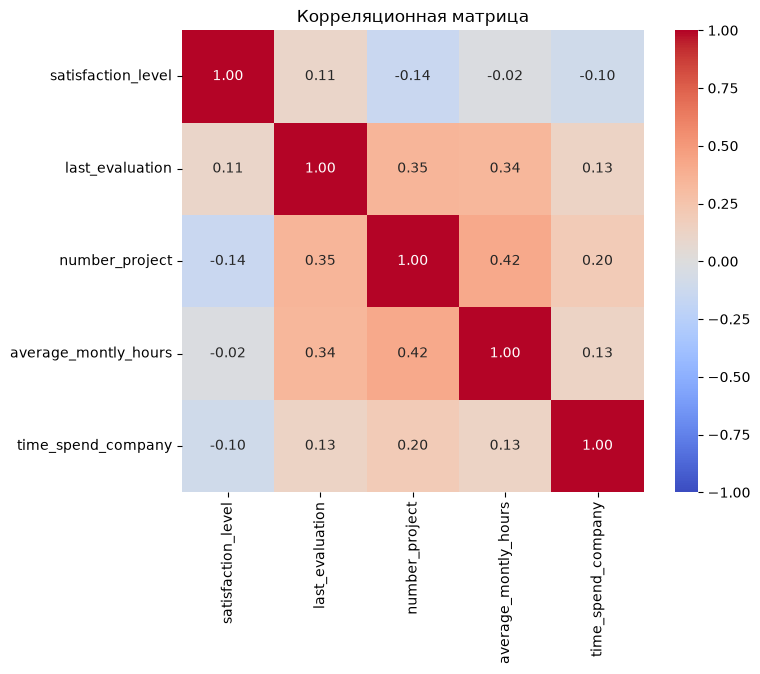

In [5]:
quant = ['satisfaction_level', 'last_evaluation', 'number_project',
         'average_montly_hours', 'time_spend_company']
corr = hr[quant].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Корреляционная матрица')
plt.show()

In [6]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)

print('Самые скоррелированные:     ', pairs.index[0], round(pairs.iloc[0], 3))
print('Наименее скоррелированные:  ', pairs.index[-1], round(pairs.iloc[-1], 3))
pairs

Самые скоррелированные:      ('number_project', 'average_montly_hours') 0.417
Наименее скоррелированные:   ('satisfaction_level', 'average_montly_hours') -0.02


number_project        average_montly_hours    0.417
last_evaluation       number_project          0.349
                      average_montly_hours    0.340
number_project        time_spend_company      0.197
satisfaction_level    number_project         -0.143
last_evaluation       time_spend_company      0.132
average_montly_hours  time_spend_company      0.128
satisfaction_level    last_evaluation         0.105
                      time_spend_company     -0.101
                      average_montly_hours   -0.020
dtype: float64

**Вывод.** Две самые скоррелированные переменные — `number_project` и `average_montly_hours` (r ≈ 0.42): больше проектов — больше часов. Две наименее скоррелированные — `satisfaction_level` и `average_montly_hours` (r ≈ −0.02), связи практически нет. В целом количественные признаки связаны слабо.

### 4. Количество сотрудников в каждом департаменте

In [7]:
dep_counts = hr['department'].value_counts()
dep_counts

department
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64

### 5. Распределение сотрудников по зарплатам

        count  share
salary              
low      7316  0.488
medium   6446  0.430
high     1237  0.082


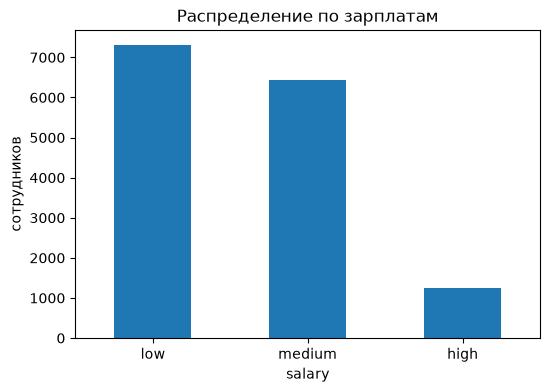

In [8]:
salary_order = ['low', 'medium', 'high']
salary_counts = hr['salary'].value_counts().reindex(salary_order)
print(pd.DataFrame({'count': salary_counts, 'share': salary_counts / len(hr)}))

salary_counts.plot.bar(title='Распределение по зарплатам', rot=0, figsize=(6, 4))
plt.ylabel('сотрудников')
plt.show()

### 6. Распределение по зарплатам в каждом департаменте

In [9]:
dep_salary = pd.crosstab(hr['department'], hr['salary'])[salary_order]
dep_salary

salary,low,medium,high
department,,,
IT,609,535,83
RandD,364,372,51
accounting,358,335,74
hr,335,359,45
management,180,225,225
marketing,402,376,80
product_mng,451,383,68
sales,2099,1772,269
support,1146,942,141


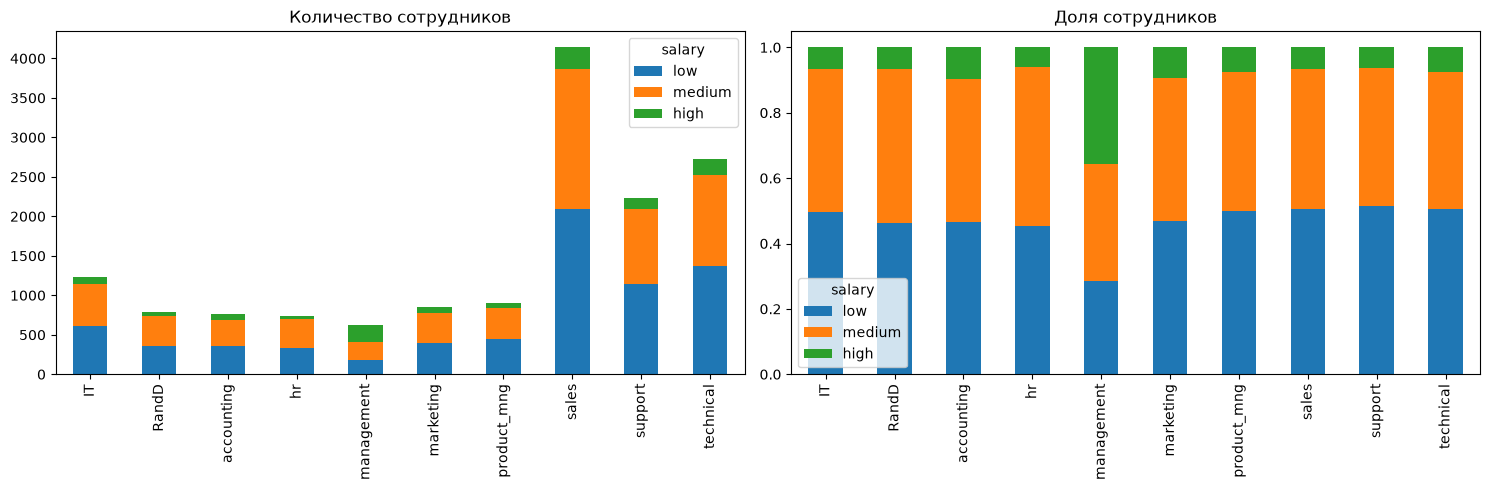

In [10]:
dep_salary_share = dep_salary.div(dep_salary.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dep_salary.plot.bar(stacked=True, ax=axes[0], title='Количество сотрудников')
dep_salary_share.plot.bar(stacked=True, ax=axes[1], title='Доля сотрудников')
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

### 7. Гипотеза: сотрудники с высоким окладом проводят на работе больше времени, чем с низким

- H0: среднее `average_montly_hours` у high ≤ low
- H1: среднее у high > low

Односторонний t-тест Уэлча (дисперсии не предполагаются равными) и, для надёжности, непараметрический тест Манна–Уитни. Уровень значимости α = 0.05.

In [11]:
high = hr.loc[hr['salary'] == 'high', 'average_montly_hours']
low  = hr.loc[hr['salary'] == 'low',  'average_montly_hours']
print(f'high: n={len(high)}, mean={high.mean():.2f}')
print(f'low:  n={len(low)}, mean={low.mean():.2f}')

t = stats.ttest_ind(high, low, equal_var=False, alternative='greater')
u = stats.mannwhitneyu(high, low, alternative='greater')
print(f't-тест Уэлча:  t={t.statistic:.3f}, p={t.pvalue:.4f}')
print(f'Манн–Уитни:    U={u.statistic:.0f}, p={u.pvalue:.4f}')

alpha = 0.05
if t.pvalue < alpha:
    print('Отвергаем H0: сотрудники с высоким окладом работают больше.')
else:
    print('Нет оснований отвергнуть H0: сотрудники с высоким окладом не проводят на работе больше времени.')

high: n=1237, mean=199.87
low:  n=7316, mean=201.00
t-тест Уэлча:  t=-0.762, p=0.7770
Манн–Уитни:    U=4507096, p=0.5879
Нет оснований отвергнуть H0: сотрудники с высоким окладом не проводят на работе больше времени.


**Вывод.** Среднее число часов у сотрудников с высоким (≈199.9) и низким (≈201.0) окладом практически одинаково, p-value ≫ 0.05 в обоих тестах. Гипотеза о том, что высокооплачиваемые сотрудники проводят на работе больше времени, **не подтверждается**.

### 8. Показатели среди уволившихся и не уволившихся

In [12]:
left_stats = hr.groupby('left').agg(
    promotion_share=('promotion_last_5years', 'mean'),
    avg_satisfaction=('satisfaction_level', 'mean'),
    avg_projects=('number_project', 'mean'),
).rename(index={0: 'остались', 1: 'уволились'})
left_stats

,promotion_share,avg_satisfaction,avg_projects
left,,,
остались,0.026,0.667,3.787
уволились,0.005,0.440,3.856


### 9. Разделение на обучающую и тестовую выборки
Признаки — все, кроме `department`, `salary` и целевой `left`. 25% данных в тест, стратификация по `left`.

In [13]:
X = hr.drop(columns=['left', 'department', 'salary'])
y = hr['left']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(11249, 7) (3750, 7)


### 10. Модель LDA

In [14]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

pd.Series(lda.coef_[0], index=X.columns, name='coef').sort_values()

satisfaction_level      -4.518
Work_accident           -1.075
promotion_last_5years   -0.970
number_project          -0.237
average_montly_hours     0.004
time_spend_company       0.231
last_evaluation          0.687
Name: coef, dtype: float64

### 11. Качество модели на тестовой выборке (accuracy)

In [15]:
y_pred = lda.predict(X_test)
acc = accuracy_score(y_test, y_pred)
baseline = 1 - y_test.mean()
print(f'Accuracy LDA:                       {acc:.3f}')
print(f'Accuracy константы «не уволился»:   {baseline:.3f}')

Accuracy LDA:                       0.762
Accuracy константы «не уволился»:   0.762


In [16]:
pd.DataFrame(confusion_matrix(y_test, y_pred),
             index=['факт: остался', 'факт: уволился'],
             columns=['прогноз: остался', 'прогноз: уволился'])

,прогноз: остался,прогноз: уволился
факт: остался,2629,228
факт: уволился,666,227


**Вывод.** Accuracy LDA на тесте ≈ 0.76 — на уровне наивного прогноза «никто не уволился» (≈ 0.76, классы несбалансированы). По матрице ошибок модель находит лишь около четверти уволившихся: зависимость увольнения от признаков нелинейная (например, увольняются и перегруженные, и недогруженные сотрудники), а LDA строит линейную границу. Главный фактор — низкая удовлетворённость (самый большой по модулю отрицательный коэффициент).